## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema
Un centro de cómputo recibe diferentes tareas que deben ser procesadas por sus servidores.

Cada tarea tiene:

Código.

Nombre.

Prioridad.<br><br>
####CONDICIONES
1. El Heap deberá implementarse utilizando un arreglo.
2. No se deben utilizar nodos ni punteros para representar el Heap.
3. Se deberá implementar manualmente MAX-HEAPIFY.
4. Se deberá implementar manualmente BUILD-MAX-HEAP.
5. Se deberá implementar MAXIMUM.
6. Se deberá implementar EXTRACT-MAX.
7. Se deberá implementar la inserción de una nueva tarea.
8. Se deberá implementar manualmente HEAPSORT.
9. No se permite utilizar heapq.
10. No se permite utilizar sort() ni sorted() para HeapSort.


## 2) Requerimientos
REQUERIMIENTOS FUNCIONALES

RQF01: REGISTRO DE LAS TAREAS- El programa debe pedirle al usuario cuántas tareas quiere ingresar y, para cada una, solicitar su código, su nombre y un número de prioridad.

RQF02: CONSTRUCCION DEL MAX-HEAP- A partir de las tareas ingresadas, el programa debe organizar los datos en forma de Max-Heap utilizando las funciones manuales MAX-HEAPIFY y BUILD-MAX-HEAP. Esto debe asegurar que cualquier tarea en el árbol tenga una prioridad mayor o igual que la de sus hijos.

RQF03: CONSULTA DE LA TAREA MAS IMPORTANTE- El programa debe poder mostrar en pantalla cuál es la tarea que está en la cima del heap (la de mayor prioridad) sin borrarla de la lista.

RQF04: PROCESAMIENTO DE LA TAREA MAS IMPORTANTE- El programa debe poder sacar la tarea de mayor prioridad para indicar que ya fue procesada, y luego reacomodar automáticamente el heap para no perder su forma.

RQF05: AGREGAR NUEVA TAREA- El sistema debe permitir añadir otra tarea con su respectiva prioridad en cualquier momento, colocándola en el lugar que le corresponda para que el Max-Heap siga funcionando bien.

RQF06: ORDEN DEL HEAPSORT- El programa debe aplicar el algoritmo HEAPSORT usando el heap para ordenar las prioridades y tareas de menor a mayor de forma manual.

RQF07: VISUALIZACION RESULTADOS- El programa debe imprimir claramente la lista inicial, cómo queda el Max-Heap, un dibujo sencillo del árbol con las prioridades, los resultados de consultar y extraer tareas, y la lista final ordenada.

REQUERIMIENTOS NO FUNCIONALES

RQNF01: Eficiencia- El programa debe realizar las operaciones de los árboles de forma eficiente.

RQNF02:Mantenibilidad- El código debe estar organizado y ser fácil de modificar.

RQNF03:Corrección- El programa debe construir correctamente el Max-Heap y la cola de prioridad, asegurando que se cumpla la propiedad de Max-Heap en todas las operaciones (registro, extracción e inserción) sin utilizar la librería.

RQNF04:Lenguaje- El programa se desarrollará en Python por su facilidad de uso y por permitir implementar y visualizar los árboles de forma sencilla.



## 3) Historias de usuario **[2 pts]**
### HU1, registrar las tareas:
pide n y cada tarea, las guarda como diccionarios en orden de ingreso, muestra la lista original y reinicia la lista si se repite la opción.
### HU2, construir el Max-Heap
valida que haya tareas, construye [10, 7, 8, 3, 4] a partir de [8, 4, 10, 3, 7] y muestra el heap como lista y como árbol
### HU3, consultar y procesar la tarea de mayor prioridad
muestra la raíz sin eliminarla, luego la extrae y reorganiza el heap ([10, 7, 8, 3, 4] pasa a [8, 7, 4, 3]).
### HU4, insertar una nueva tarea:

la tarea sube mientras su padre tenga menor prioridad y una prioridad 12 queda en la raíz
### HU5, ordenar con HeapSort
Genera la lista ordenada [3, 4, 7, 8, 10] trabajando sobre una copia independiente para no alterar el Heap original. Se implementa desde cero mediante la lógica del algoritmo (intercambios y reacomodo) sin usar funciones nativas como sort(), sorted() ni bibliotecas externas.

## 4) Diagramas de flujo **[5 pts]**
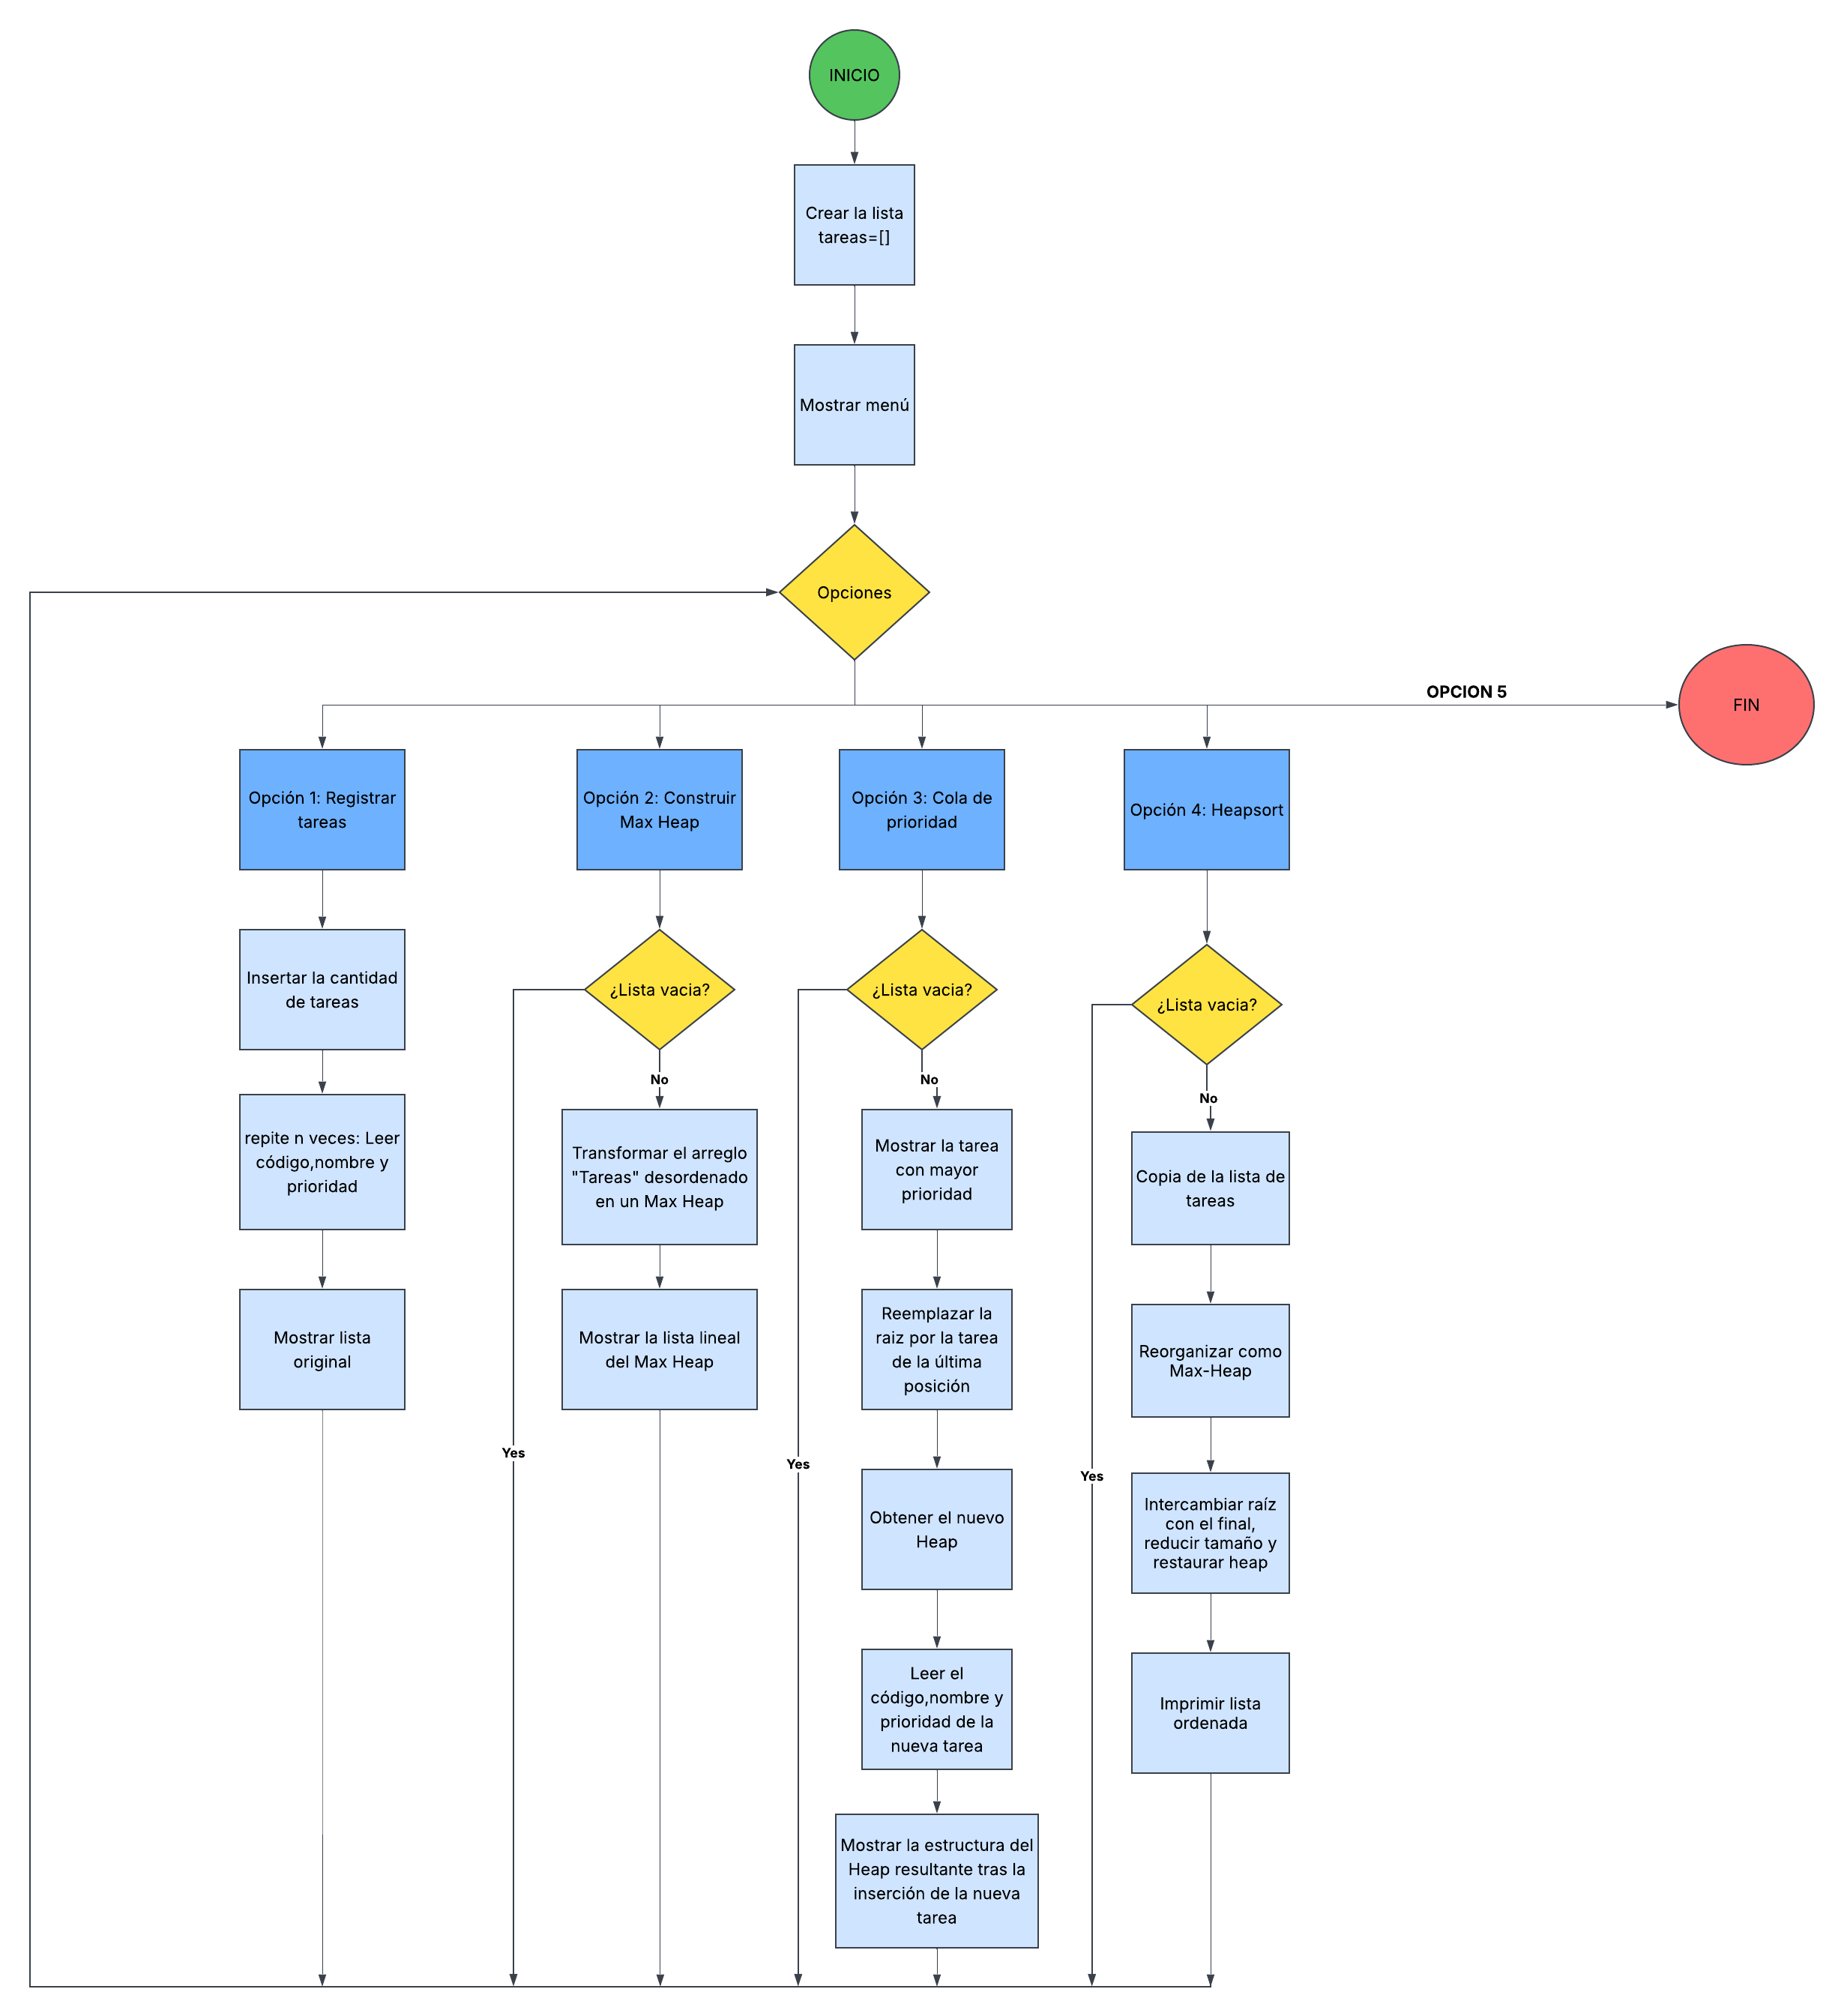

### 5) Análisis de complejidad
Mejor caso: O(1) para consultas (MAXIMUM) o cuando un elemento insertado  ya cumple con la propiedad del montículo y no requiere ningún desplazamiento en el árbol.
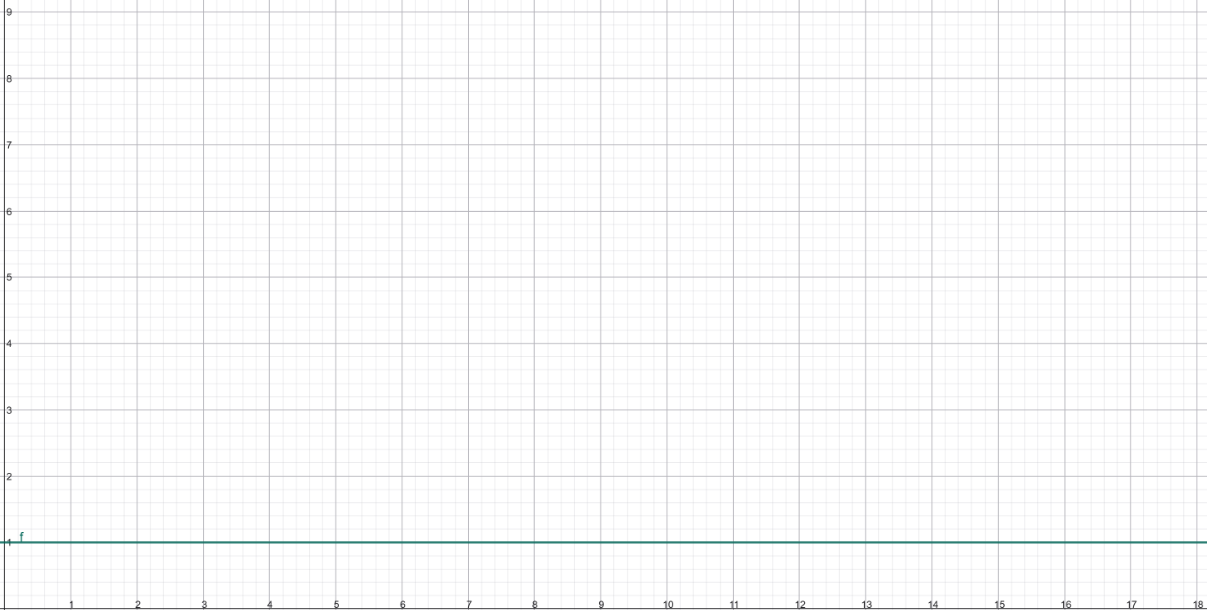

Peor caso: O(\log n) para inserciones, extracciones y heapify cuando un elemento debe recorrer toda la altura del árbol y O(n \log n) para el orden completo (HEAPSORT).


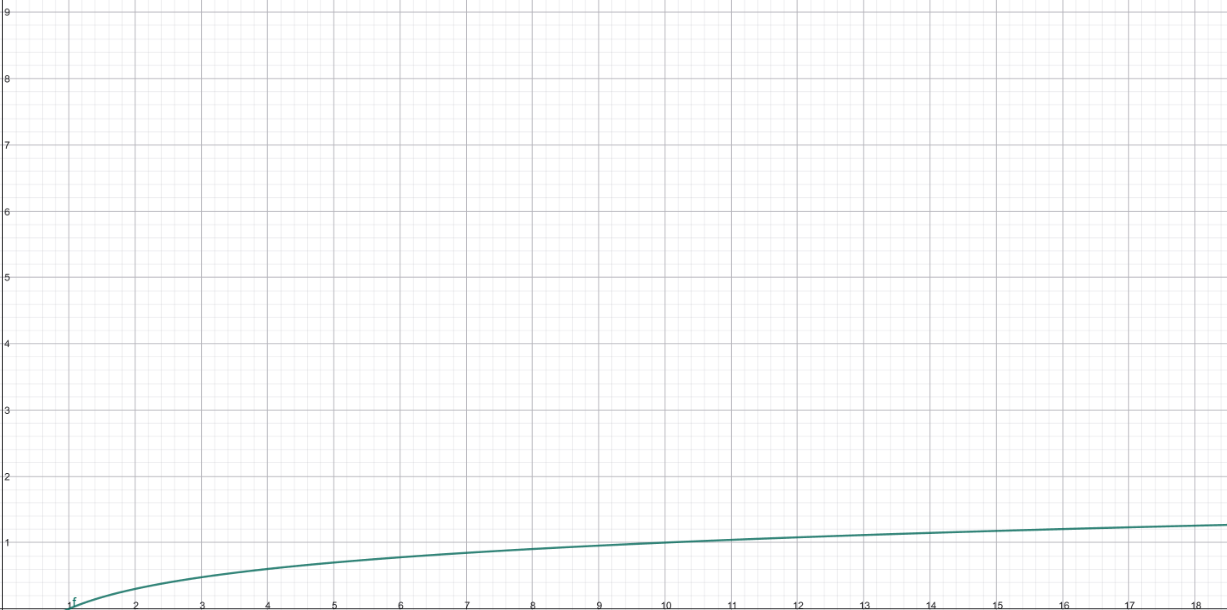

## 6) Código funcional



In [ ]:
  import math

def padre(i):
    return (i - 1) // 2
def izq(i):
    return 2 * i + 1
def der(i):
    return 2 * i + 2

def max_heap(A, i, heap_size):
    l = izq(i)
    r = der(i)
    largest = i
    if l < heap_size and A[l]["prioridad"] > A[largest]["prioridad"]:
        largest = l
    if r < heap_size and A[r]["prioridad"] > A[largest]["prioridad"]:
        largest = r
    if largest != i:
        A[i], A[largest] = A[largest], A[i]
        max_heap(A, largest, heap_size)

def const_max_heap(A):
    heap_size = len(A)
    for i in range(heap_size // 2 - 1, -1, -1):
        max_heap(A, i, heap_size)

def arbol(A):
    if not A: return
    niveles = math.floor(math.log2(len(A))) + 1
    ancho = 2 ** niveles * 2
    for i in range(niveles):
        inicio = 2**i - 1
        fin = min(2**(i+1) - 1, len(A))
        nodos = A[inicio:fin]
        espacio = " " * (ancho // (2**(i+1)))
        print(espacio + espacio.join([str(n["prioridad"]) for n in nodos]))
        if i < niveles - 1:
            print(espacio + espacio.join(["/ \\" for _ in nodos]))

def max(A):
    return A[0] if A else None

def extr_priori(A):
    if not A: return None
    max_t = A[0]
    A[0] = A[-1]
    A.pop()
    max_heap(A, 0, len(A))
    return max_t

def HEAP_INCREASE_KEY(A, i, tarea):
    A[i] = tarea
    while i > 0 and A[padre(i)]["prioridad"] < A[i]["prioridad"]:
        A[i], A[padre(i)] = A[padre(i)], A[i]
        i = padre(i)

def insertar(A, tarea):
    A.append({"prioridad": float('-inf')})
    HEAP_INCREASE_KEY(A, len(A) - 1, tarea)

def heapsort(A):
    const_max_heap(A)
    heap_size = len(A)
    for i in range(len(A) - 1, 0, -1):
        A[0], A[i] = A[i], A[0]
        heap_size -= 1
        max_heap(A, 0, heap_size)

def main():
    tareas = []

    while True:
        print("\n--- MENÚ DEL CENTRO DE CÓMPUTO ---")
        print("1. Registrar tareas (Punto 1)")
        print("2. Construir Max-Heap (Punto 2)")
        print("3. Cola de prioridad (Punto 3)")
        print("4. HeapSort (Punto 4)")
        print("5. Salir")
        op = input("Elige una opción: ")

        if op == '1':
            tareas = []
            n = int(input("Cantidad de tareas: "))
            for _ in range(n):
                c = input("Código: ")
                nom = input("Nombre: ")
                p = int(input("Prioridad: "))
                tareas.append({"codigo": c, "nombre": nom, "prioridad": p})
            print("Lista original:", [t["prioridad"] for t in tareas])

        elif op == '2':
            if not tareas:
                print("Registra tareas primero.")
                continue
            const_max_heap(tareas)
            print("Max-Heap:", [t["prioridad"] for t in tareas])
            arbol(tareas)

        elif op == '3':
            if not tareas:
                print("Registra y construye el Heap primero.")
                continue

            tarea_max = max(tareas)
            print(f"\nA. Mayor prioridad: {tarea_max['codigo']} - {tarea_max['nombre']} (P: {tarea_max['prioridad']})")

            tarea_proc = extr_priori(tareas)
            print(f"B. Tarea procesada: {tarea_proc['codigo']} - {tarea_proc['nombre']}")
            print("   Nuevo Heap:", [t["prioridad"] for t in tareas])

            print("C. Insertar nueva tarea:")
            c = input("   Código: ")
            nom = input("   Nombre: ")
            p = int(input("   Prioridad: "))
            insertar(tareas, {"codigo": c, "nombre": nom, "prioridad": p})
            print("   Heap tras inserción:", [t["prioridad"] for t in tareas])

        elif op == '4':
            if not tareas:
                print("Registra tareas primero.")
                continue
            lista_clon = [dict(t) for t in tareas]
            heapsort(lista_clon)
            print("Lista ordenada:", [t["prioridad"] for t in lista_clon])

        elif op == '5':
            break

main()


## 7) Tests aplicados **[15 pts]**

In [ ]:
#Pruebas realizadas con las siguientes tareas, codigos y prioridades
#T01 - Compilar proyecto - Prioridad 8
#T02 - Generar backup - Prioridad 4
#T03 - Renderizar video - Prioridad 10
#T04 - Procesar correos - Prioridad 3
#T05 - Ejecutar pruebas - Prioridad 7
import math

def padre(i):
    return (i - 1) // 2
def izq(i):
    return 2 * i + 1
def der(i):
    return 2 * i + 2

def max_heap(A, i, heap_size):
    l = izq(i)
    r = der(i)
    largest = i
    if l < heap_size and A[l]["prioridad"] > A[largest]["prioridad"]:
        largest = l
    if r < heap_size and A[r]["prioridad"] > A[largest]["prioridad"]:
        largest = r
    if largest != i:
        A[i], A[largest] = A[largest], A[i]
        max_heap(A, largest, heap_size)

def const_max_heap(A):
    heap_size = len(A)
    for i in range(heap_size // 2 - 1, -1, -1):
        max_heap(A, i, heap_size)

def arbol(A):
    if not A: return
    niveles = math.floor(math.log2(len(A))) + 1
    ancho = 2 ** niveles * 2
    for i in range(niveles):
        inicio = 2**i - 1
        fin = min(2**(i+1) - 1, len(A))
        nodos = A[inicio:fin]
        if not nodos: continue
        espacio = " " * (ancho // (2**(i+1)))
        print(espacio + espacio.join([str(n["prioridad"]) for n in nodos]))
        if i < niveles - 1:
            print(espacio + espacio.join(["/ \\" for _ in nodos]))

def max_prioridad(A):
    return A[0] if A else None

def extr_priori(A):
    if not A: return None
    max_t = A[0]
    A[0] = A[-1]
    A.pop()
    if A:
        max_heap(A, 0, len(A))
    return max_t

def increm(A, i, tarea):
    A[i] = tarea
    while i > 0 and A[padre(i)]["prioridad"] < A[i]["prioridad"]:
        A[i], A[padre(i)] = A[padre(i)], A[i]
        i = padre(i)

def insertar(A, tarea):
    A.append({"prioridad": float('-inf')})
    increm(A, len(A) - 1, tarea)

def heapsort(A):
    const_max_heap(A)
    heap_size = len(A)
    for i in range(len(A) - 1, 0, -1):
        A[0], A[i] = A[i], A[0]
        heap_size -= 1
        max_heap(A, 0, heap_size)

def main():
    print("\t REGISTRO DE TAREAS")
    tareas = [
        {"codigo": "T01", "nombre": "Compilar proyecto", "prioridad": 8},
        {"codigo": "T02", "nombre": "Generar backup", "prioridad": 4},
        {"codigo": "T03", "nombre": "Renderizar video", "prioridad": 10},
        {"codigo": "T04", "nombre": "Procesar correos", "prioridad": 3},
        {"codigo": "T05", "nombre": "Ejecutar pruebas", "prioridad": 7}
    ]
    print("Lista original de prioridades:", [t["prioridad"] for t in tareas])

    print("\n\n\t CONSTRUIR EL MAX-HEAP")
    const_max_heap(tareas)
    print("Max-Heap:", [t["prioridad"] for t in tareas])
    print("Representación del árbol:")
    arbol(tareas)

    print("\n\n\t COLA DE PRIORIDAD")
    tarea_max = max_prioridad(tareas)
    print(f"-Mayor prioridad: {tarea_max['codigo']} - {tarea_max['nombre']} (Prioridad: {tarea_max['prioridad']})")

    tarea_proc = extr_priori(tareas)
    print(f"-Tarea procesada: {tarea_proc['codigo']} - {tarea_proc['nombre']}")
    print("   Nuevo Heap:", [t["prioridad"] for t in tareas])

    nueva_tarea = {"codigo": "T06", "nombre": "Actualizar servidor", "prioridad": 12}
    print(f"-Insertando nueva tarea: {nueva_tarea['codigo']} - {nueva_tarea['nombre']} (Prioridad: {nueva_tarea['prioridad']})")
    insertar(tareas, nueva_tarea)
    print("   Heap tras inserción:", [t["prioridad"] for t in tareas])

    print("\n\n\t HEAPSORT")
    lista_clon = [dict(t) for t in tareas]
    heapsort(lista_clon)
    print("Lista ordenada:", [t["prioridad"] for t in lista_clon])

main()


	 REGISTRO DE TAREAS
Lista original de prioridades: [8, 4, 10, 3, 7]


	 CONSTRUIR EL MAX-HEAP
Max-Heap: [10, 7, 8, 3, 4]
Representación del árbol:
        10
        / \
    7    8
    / \    / \
  3  4


	 COLA DE PRIORIDAD
-Mayor prioridad: T03 - Renderizar video (Prioridad: 10)
-Tarea procesada: T03 - Renderizar video
   Nuevo Heap: [8, 7, 4, 3]
-Insertando nueva tarea: T06 - Actualizar servidor (Prioridad: 12)
   Heap tras inserción: [12, 8, 4, 3, 7]


	 HEAPSORT
Lista ordenada: [3, 4, 7, 8, 12]
